<div style="font-family:Georgia, 'Times New Roman', Times, serif; text-align:center; line-height:1.6; color:#111;">
        <div style="border-bottom: 3px double #FF7500; padding-bottom: 15px; width: 80%; margin: 0 auto;">
            <span style="color:#FF7500; font-size:32px; font-weight:normal; font-variant: small-caps;">University of Cyprus</span>
            <br>
            <span style="color:#ccc; font-size:18px; font-style:italic;">Department of Computer Science
            </span>
        </div>
        <br>
        <div style="background-color: #f4f6f9; padding: 15px; border-radius: 4px; width: 60%; margin: 0 auto; border-left: 5px solid #0033cc;">
            <span style="color:#0033cc; font-size:22px; font-weight:bold;">Computer Vision</span>
            <br>
            <span style="font-size:16px;">Instructor: <strong>Dr. Antonis Savva</strong></span>
            <br>
            <span style="font-size:14px; color: #666;">Fall Semester 2026</span>
        </div>
        <br><br>
        <span style="color:#b30000; font-size:48px; font-weight:bold; letter-spacing: -1px;">Assignment 01</span>
        <br>
        <span style="font-size:16px; font-weight:bold; color: #555;">Due Date: October 18<sup>th</sup></span>
        <br><br><br>
        <div style="border-top: 1px solid #ccc; width: 40%; margin: 0 auto; padding-top: 10px;">
            <span style="font-size:20px; font-weight:bold; color: #ccc">Kian Izadpanah</span>
            <br>
            <span style="font-size:16px; font-family: monospace; color: #ccc;">ID: UC1385257</span>
        </div>
</div>

### Setup

First I import the libraries and write some small helper functions:

- `read_image` reads an image from the data folder. If the file is missing, it stops with a clear error.
- `save_image` saves one image in `outputs/` with `cv2.imwrite`.
- `to_rgb` changes BGR to RGB, because OpenCV uses BGR but matplotlib expects RGB.
- `show_grid` shows a list of images in a grid and can also save the figure for the report.

`RESULTS` is a dictionary where I keep all the numbers for the report.

In [1]:
import os, json, math, time
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

IMG_DIR = "assignment-1-data"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titlesize": 10, "font.size": 9})
RESULTS = {}

print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)


def read_image(name, flags=cv2.IMREAD_COLOR):
    path = os.path.join(IMG_DIR, name)
    img = cv2.imread(path, flags)
    if img is None:
        raise FileNotFoundError(f"Could not read '{path}'. Put the course images in '{IMG_DIR}/'.")
    return img


def save_image(name, img):
    cv2.imwrite(os.path.join(OUT_DIR, name), img)


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show_grid(images, titles, ncols, fig_name=None, cell=3.2, cmap="gray", interp="nearest"):
    nrows = math.ceil(len(images) / ncols)
    aspect = max(im.shape[0] / im.shape[1] for im in images)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell * ncols, nrows * (cell * aspect + 0.35)),
                             squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, t in zip(axes.ravel(), images, titles):
        ax.imshow(to_rgb(img), cmap=cmap, interpolation=interp, vmin=0, vmax=255)
        ax.set_title(t)
    fig.tight_layout()
    if fig_name:
        fig.savefig(os.path.join(OUT_DIR, fig_name))
    plt.show()

OpenCV 4.13.0 | NumPy 2.4.3 | Matplotlib 3.10.8


---
# Exercise 1 – Programming exercises

## 1(a) Image resizing with nearest-neighbour interpolation

The new image has size $w \times h$ and the original has size $W \times H$.
For every pixel $(x, y)$ of the new image, I find the matching position in the original image.
I use the centre of each pixel, so both images cover the same area:

$$x_{src} = (x + 0.5)\,\frac{W}{w} - 0.5, \qquad y_{src} = (y + 0.5)\,\frac{H}{h} - 0.5 .$$

These positions are usually not whole numbers. Nearest-neighbour just takes the pixel at the closest
integer position, $\big(\lfloor x_{src} + 0.5 \rfloor,\ \lfloor y_{src} + 0.5 \rfloor\big)$.
I also clip the position to the image, so I never read outside of it.

The function `nn_resize` makes an empty image with the same number of channels as the input
(it works for grayscale and colour), then loops over all the pixels and copies the nearest one.

In [2]:
def nn_resize(image, w, h):
    H, W = image.shape[:2]
    out = np.zeros((h, w) + image.shape[2:], dtype=image.dtype)
    scale_x, scale_y = W / w, H / h

    for y in range(h):
        src_y = (y + 0.5) * scale_y - 0.5
        src_y = math.floor(src_y + 0.5)
        src_y = min(max(src_y, 0), H - 1)
        
        for x in range(w):
            src_x = (x + 0.5) * scale_x - 0.5
            src_x = math.floor(src_x + 0.5)
            src_x = min(max(src_x, 0), W - 1)
            
            out[y, x] = image[src_y, src_x]
    return out

To check my loop version, I also wrote `nn_resize_fast`. It does the same mapping but with NumPy
indexing instead of loops. I only use it to check that the loop version gives exactly the same
image, and to compare the speed.

Then I load `goldfish.jpg` and do a small test: if I make a $2 \times 3$ image twice as big,
every pixel should become a $2 \times 2$ block.

In [3]:
def nn_resize_fast(image, w, h):
    H, W = image.shape[:2]
    ys = np.clip(np.floor((np.arange(h) + 0.5) * H / h), 0, H - 1).astype(int)
    xs = np.clip(np.floor((np.arange(w) + 0.5) * W / w), 0, W - 1).astype(int)
    return image[ys[:, None], xs[None, :]]

tiny = np.arange(6, dtype=np.uint8).reshape(2, 3)
print(nn_resize(tiny, 6, 4))
assert np.array_equal(nn_resize(tiny, 6, 4), np.kron(tiny, np.ones((2, 2), np.uint8)))
print("Test passed: every pixel became a 2x2 block.")

[[0 0 1 1 2 2]
 [0 0 1 1 2 2]
 [3 3 4 4 5 5]
 [3 3 4 4 5 5]]
Test passed: every pixel became a 2x2 block.


In [4]:
goldfish = read_image("goldfish.jpg")
H0, W0 = goldfish.shape[:2]
print(f"goldfish.jpg: {W0} x {H0} pixels, {goldfish.shape[2]} channels")
RESULTS["goldfish_size"] = [W0, H0]

goldfish.jpg: 1250 x 905 pixels, 3 channels


### Downscaling

I make the image 1/2, 1/4 and 1/8 of its size. Each result is saved to disk.
In the figure all of them are drawn at the same display size, so it is easy to see how much detail is lost.
For every size I also check that the loop version and the NumPy version give the same image.

1/2: 625 x 452  (0.21 s with loops)
1/4: 312 x 226  (0.05 s with loops)
1/8: 156 x 113  (0.01 s with loops)


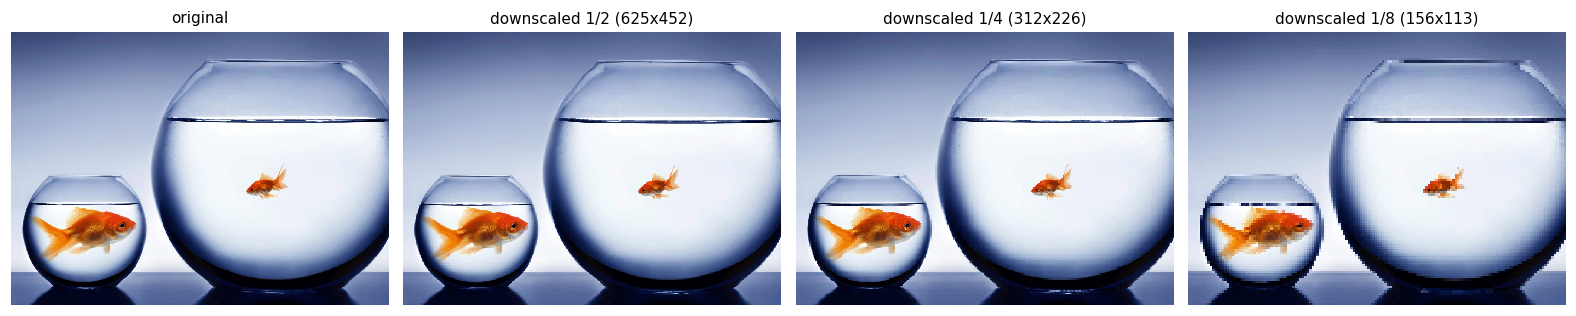

In [5]:
down = {}
for f in [2, 4, 8]:
    w, h = W0 // f, H0 // f
    t0 = time.time()
    down[f] = nn_resize(goldfish, w, h)
    t_loop = time.time() - t0
    assert np.array_equal(down[f], nn_resize_fast(goldfish, w, h))
    save_image(f"1a_down_x{f}.png", down[f])
    print(f"1/{f}: {w} x {h}  ({t_loop:.2f} s with loops)")

show_grid([goldfish] + [down[f] for f in [2, 4, 8]],
          ["original"] + [f"downscaled 1/{f} ({down[f].shape[1]}x{down[f].shape[0]})" for f in [2, 4, 8]],
          ncols=4, fig_name="1a_downscale.png", cell=3.6)

### Upscaling

The centre of the image is only water, so upscaling it would not show much. Instead, I take a small
$64 	imes 48$ crop around the eye of the small fish in the big bowl, because it has sharp edges and fine detail.
I keep the crop small so the pixel blocks are easy to see in the figure. I make this crop 4 and 8 times bigger. Next to it I show OpenCV's bilinear interpolation (`cv2.resize`), only to compare.

I also take the 1/8 image and make it big again (back to the original size) to see if the lost detail comes back.
To put a number on this, I compute the mean absolute error between the original and the image after
"down and up again", for 1/2, 1/4 and 1/8.

Mean absolute error after down + up: {'1/2': 1.42, '1/4': 2.51, '1/8': 4.25}


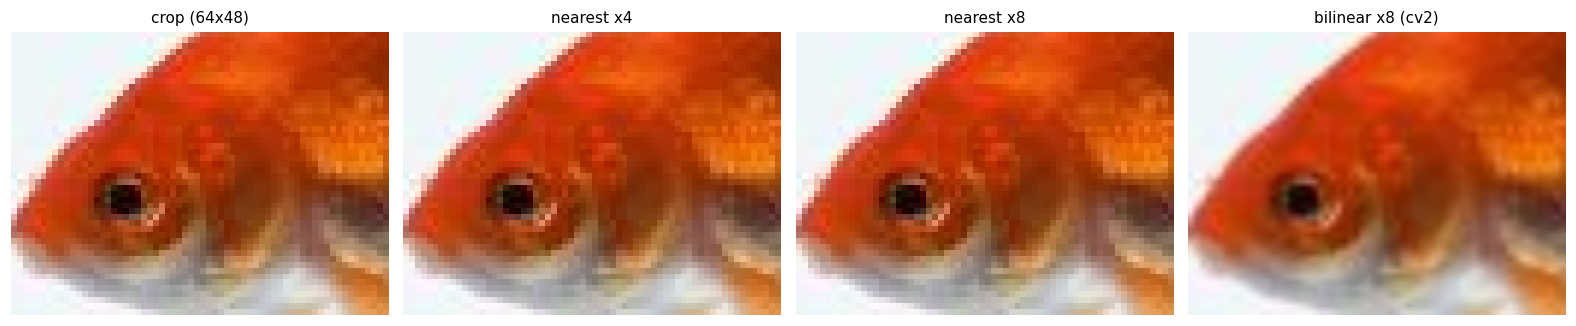

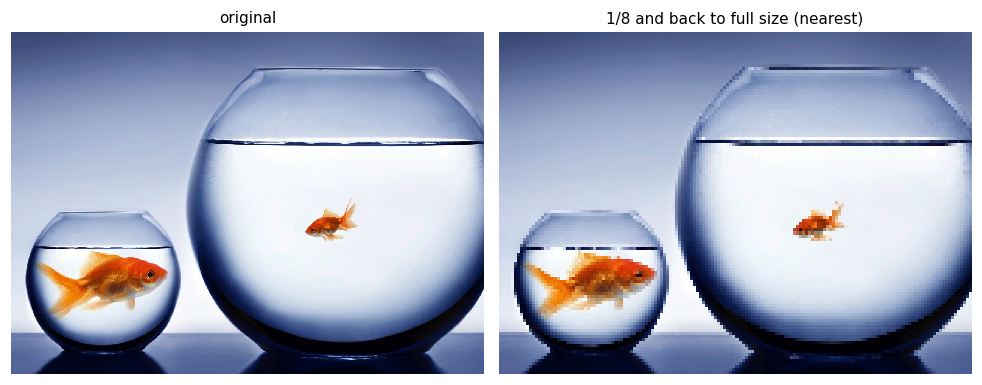

In [6]:
uy, ux = int(0.575 * H0), int(0.648 * W0)
crop = goldfish[uy - 24: uy + 24, ux - 32: ux + 32]

up4 = nn_resize(crop, crop.shape[1] * 4, crop.shape[0] * 4)
up8 = nn_resize(crop, crop.shape[1] * 8, crop.shape[0] * 8)
up8_bilinear = cv2.resize(crop, (crop.shape[1] * 8, crop.shape[0] * 8), interpolation=cv2.INTER_LINEAR)
for name, im in [("1a_crop.png", crop), ("1a_up_x4.png", up4), ("1a_up_x8.png", up8),
                 ("1a_up_x8_bilinear_cv2.png", up8_bilinear)]:
    save_image(name, im)

back = nn_resize(down[8], W0, H0)
save_image("1a_down8_up8.png", back)

mae = {f: float(np.mean(np.abs(nn_resize(down[f], W0, H0).astype(int) - goldfish.astype(int))))
       for f in [2, 4, 8]}
print("Mean absolute error after down + up:", {f"1/{k}": round(v, 2) for k, v in mae.items()})
RESULTS["1a_roundtrip_mae"] = mae

show_grid([crop, up4, up8, up8_bilinear],
          [f"crop ({crop.shape[1]}x{crop.shape[0]})", "nearest x4", "nearest x8", "bilinear x8 (cv2)"],
          ncols=4, fig_name="1a_upscale.png", cell=3.6)
show_grid([goldfish, back], ["original", "1/8 and back to full size (nearest)"],
          ncols=2, fig_name="1a_roundtrip.png", cell=4.5)

### Aliasing when downscaling

When I downscale by $f$, nearest-neighbour keeps only one pixel from every $f \times f$ block and
throws the rest away. Thin lines and fine patterns can then turn into jagged, wrong patterns. This is called aliasing.
A simple fix is to blur the image a little *before* downscaling, so the pixel that is kept is like an
average of its neighbourhood. I compare plain nearest-neighbour with "Gaussian blur first, then nearest-neighbour"
at 1/8. I use $\sigma = f/2$ for the blur. Both results are made big again so they are easy to compare.

I also try a non-uniform resize (only the width changes, so the image is stretched), and I compare
the speed of the loop version and the NumPy version.

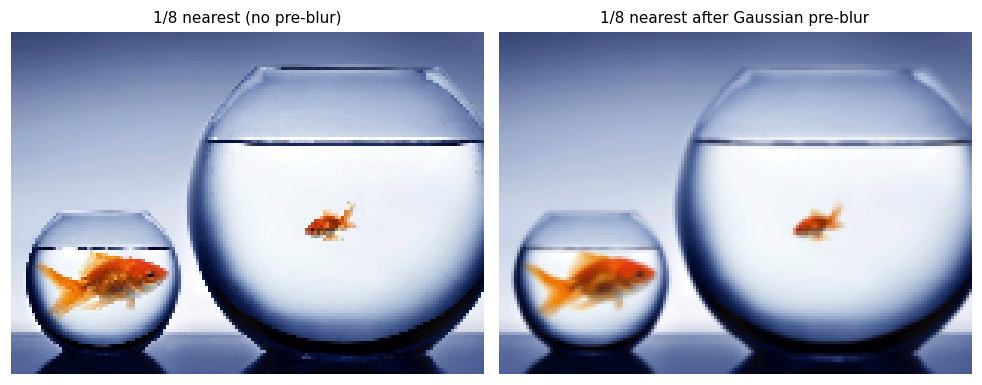

non-uniform resize: 2500 x 905
2x upscale: loops 3.24 s, NumPy indexing 65.6 ms


In [7]:
f = 8
blurred = cv2.GaussianBlur(goldfish, (0, 0), sigmaX=f / 2)
down8_blur = nn_resize(blurred, W0 // f, H0 // f)
save_image("1a_down_x8_preblur.png", down8_blur)

big_a = nn_resize(down[8], W0, H0)
big_b = nn_resize(down8_blur, W0, H0)
show_grid([big_a, big_b], ["1/8 nearest (no pre-blur)", "1/8 nearest after Gaussian pre-blur"],
          ncols=2, fig_name="1a_aliasing.png", cell=4.5)

wide = nn_resize(goldfish, W0 * 2, H0)
save_image("1a_wide_2x.png", wide)
print("non-uniform resize:", wide.shape[1], "x", wide.shape[0])

t0 = time.time(); nn_resize(goldfish, W0 * 2, H0 * 2); t_loop = time.time() - t0
t0 = time.time(); nn_resize_fast(goldfish, W0 * 2, H0 * 2); t_fast = time.time() - t0
print(f"2x upscale: loops {t_loop:.2f} s, NumPy indexing {t_fast * 1000:.1f} ms")
RESULTS["1a_time_up2"] = {"loops_s": t_loop, "numpy_ms": t_fast * 1000}

## 1(b) Image filtering with convolutions

### Box filter

An $s \times s$ box filter is an array full of ones, divided by $s^2$. So all the values add up to one,
and the filter does not change the overall brightness of the image.
I only allow odd sizes, so the filter always has a centre pixel.

In [8]:
def make_box_filter(s):
    if s < 1 or s % 2 == 0:
        raise ValueError("The filter size s must be a positive odd number (so it has a centre).")
    box = np.ones((s, s), dtype=np.float64)
    return box / box.sum()


np.set_printoptions(precision=2, suppress=True)
print(make_box_filter(5))
print("sum =", make_box_filter(5).sum())

[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]
sum = 1.0


### Convolution

Each output pixel is the dot product between the flipped filter and the image window around that pixel:

$$g(x, y) = \sum_{i=-k}^{k}\sum_{j=-k}^{k} h(i, j)\, f(x - i,\; y - j), \qquad k = \lfloor s/2 \rfloor .$$

How the function `convolve_image` works:

1. I turn the image into float numbers. If it is grayscale, I add a channel axis so the same code works for both cases.
2. I flip the filter, so it is a real convolution and not a correlation. For the box filter this changes nothing
   (it is symmetric), but it makes the function correct for any filter.
3. I pad the image with `np.pad`. There are three options for the border:
   - `"reflect"` (default): mirror the image at the border,
   - `"zero"`: put zeros around the image,
   - `"valid"`: no padding, the border is not processed, so the output is smaller.
4. For every channel and every pixel, I cut out the window, use `flatten()` on the window and the filter,
   and take their dot product with `np.dot`. The filter has one channel and is used on each colour channel on its own,
   so the output has the same number of channels as the input.
5. If the input was `uint8`, I round the result and clip it to 0–255 so the output has the same type.

In [9]:
def convolve_image(image, filt, padding="reflect"):
    img = image.astype(np.float64)
    gray = img.ndim == 2
    if gray:
        img = img[:, :, None]
    H, W, C = img.shape
    kh, kw = filt.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Use a filter with odd height and width.")
    ph, pw = kh // 2, kw // 2

    kernel = filt[::-1, ::-1].flatten()

    if padding == "reflect":
        padded = np.pad(img, ((ph, ph), (pw, pw), (0, 0)), mode="reflect")
    elif padding == "zero":
        padded = np.pad(img, ((ph, ph), (pw, pw), (0, 0)), mode="constant", constant_values=0)
    elif padding == "valid":
        padded = img
    else:
        raise ValueError("padding must be 'reflect', 'zero' or 'valid'")

    out_h, out_w = padded.shape[0] - kh + 1, padded.shape[1] - kw + 1
    out = np.zeros((out_h, out_w, C), dtype=np.float64)

    for c in range(C):
        channel = padded[:, :, c]
        for y in range(out_h):
            for x in range(out_w):
                window = channel[y:y + kh, x:x + kw]
                out[y, x, c] = np.dot(window.flatten(), kernel)

    if gray:
        out = out[:, :, 0]
    if image.dtype == np.uint8:
        out = np.clip(np.round(out), 0, 255).astype(np.uint8)
    return out

**Check.** To be sure my function is correct, I compare it with `cv2.filter2D` on a small crop.
I use `cv2.filter2D` only for this check. Note that `np.pad(mode="reflect")` is the same as
OpenCV's `BORDER_REFLECT_101`. I also check the size of the `"valid"` output.

In [10]:
test = goldfish[:120, :160]
max_diff = {}
for pad, border in [("reflect", cv2.BORDER_REFLECT_101), ("zero", cv2.BORDER_CONSTANT)]:
    ours = convolve_image(test, make_box_filter(5), padding=pad).astype(int)
    ref = cv2.filter2D(test, -1, make_box_filter(5), borderType=border).astype(int)
    max_diff[pad] = int(np.abs(ours - ref).max())
    print(f"{pad:8s}: max difference to cv2.filter2D = {max_diff[pad]} grey level(s)")
valid = convolve_image(test, make_box_filter(5), padding="valid")
print("valid output size:", valid.shape, "from input", test.shape)
RESULTS["1b_check_max_diff"] = max_diff

reflect : max difference to cv2.filter2D = 0 grey level(s)
zero    : max difference to cv2.filter2D = 0 grey level(s)
valid output size: (116, 156, 3) from input (120, 160, 3)


### Effect of the filter size

I blur `goldfish.jpg` with box filters of size 3, 5, 9, 15 and 25 (mirrored borders).
Every result is saved to disk. To measure how much detail is left, I use the variance of the Laplacian.
This is a common sharpness score: a high value means many sharp edges, a low value means a blurry image.
I also show the same crop (the small fish in the big bowl) from every result, to see the fine detail better.

 3x3 :   7.8 s   sharpness =     23.4
 5x5 :   8.1 s   sharpness =      9.1
 9x9 :   8.1 s   sharpness =      3.5
15x15:   9.1 s   sharpness =      1.9
25x25:  10.6 s   sharpness =      1.4
original: sharpness = 172.2


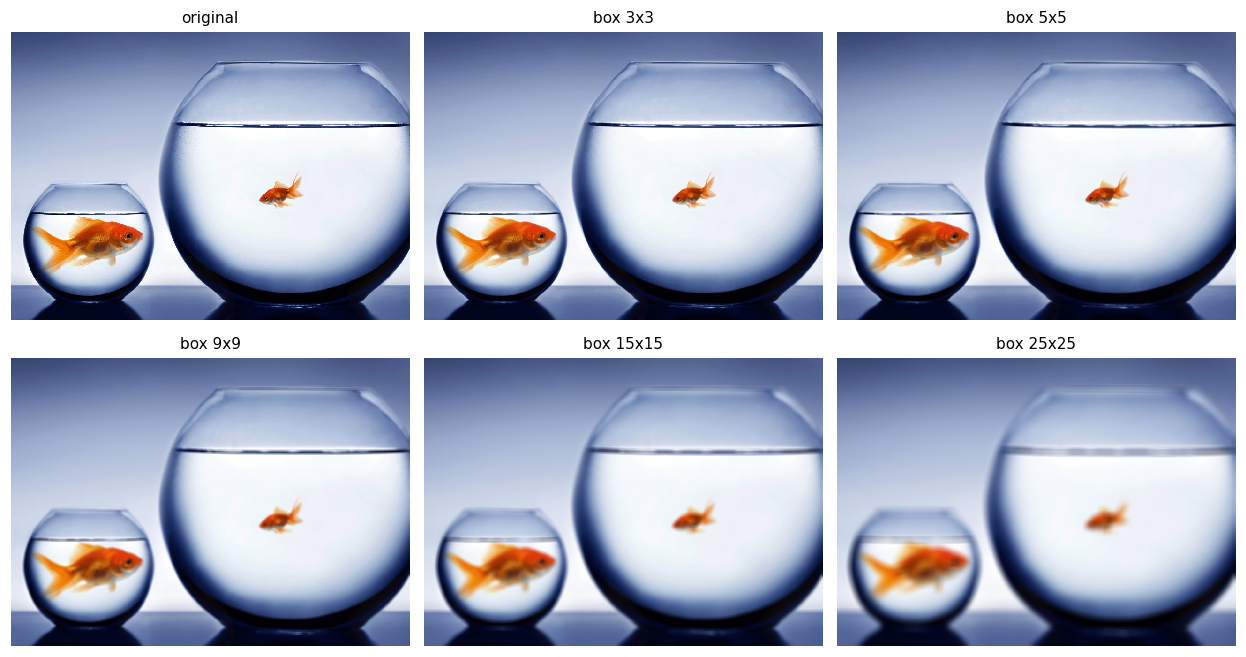

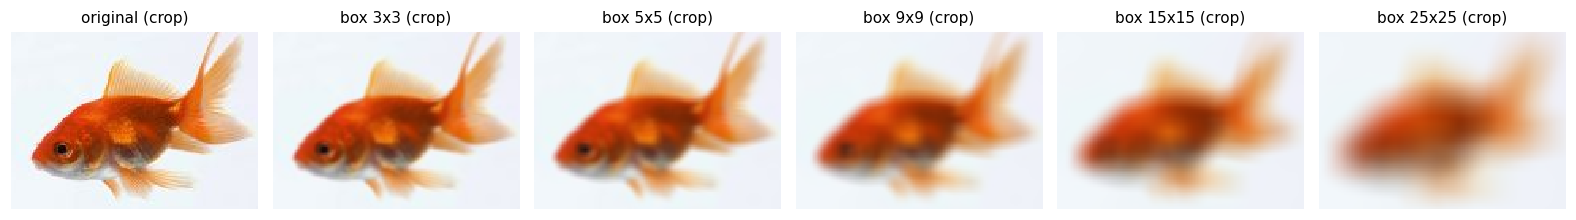

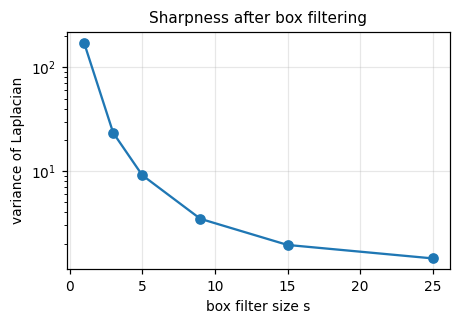

In [11]:
def sharpness(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    return float(cv2.Laplacian(g, cv2.CV_64F).var())


sizes = [3, 5, 9, 15, 25]
blurred_imgs, sharp, conv_time = {}, {"original": sharpness(goldfish)}, {}
for s in sizes:
    t0 = time.time()
    blurred_imgs[s] = convolve_image(goldfish, make_box_filter(s), padding="reflect")
    conv_time[s] = time.time() - t0
    sharp[s] = sharpness(blurred_imgs[s])
    save_image(f"1b_box_{s}x{s}.png", blurred_imgs[s])
    print(f"{s:2d}x{s:<2d}: {conv_time[s]:5.1f} s   sharpness = {sharp[s]:8.1f}")
print(f"original: sharpness = {sharp['original']:.1f}")
RESULTS["1b_sharpness"] = {str(k): v for k, v in sharp.items()}
RESULTS["1b_time_s"] = {str(k): v for k, v in conv_time.items()}

show_grid([goldfish] + [blurred_imgs[s] for s in sizes],
          ["original"] + [f"box {s}x{s}" for s in sizes], ncols=3, fig_name="1b_box_filters.png", cell=3.8)

cy, cx = int(0.56 * H0), int(0.675 * W0)
ch, cw = H0 // 8, W0 // 8
zoom = lambda im: im[cy - ch // 2: cy + ch // 2, cx - cw // 2: cx + cw // 2]
show_grid([zoom(goldfish)] + [zoom(blurred_imgs[s]) for s in sizes],
          ["original (crop)"] + [f"box {s}x{s} (crop)" for s in sizes], ncols=6,
          fig_name="1b_box_filters_crop.png", cell=2.4)

plt.figure(figsize=(4.5, 2.8))
plt.plot([1] + sizes, [sharp["original"]] + [sharp[s] for s in sizes], "o-")
plt.xlabel("box filter size s"); plt.ylabel("variance of Laplacian"); plt.yscale("log")
plt.title("Sharpness after box filtering"); plt.grid(alpha=.3)
plt.savefig(os.path.join(OUT_DIR, "1b_sharpness.png")); plt.show()

### Effect of the border handling

With a big filter, the border choice is easy to see. I use the $25 \times 25$ filter with all three options.
Zero padding mixes black pixels into the average near the border, mirroring does not, and "valid" makes the image smaller.
To measure the dark frame, I compare the mean gray level of the border band ($\lfloor s/2 \rfloor$ pixels wide)
between zero padding and mirroring.

border band of 12 px: zero padding is 27.5 grey levels darker than mirroring on average
valid output size: 1226 x 881 (input 1250 x 905 )


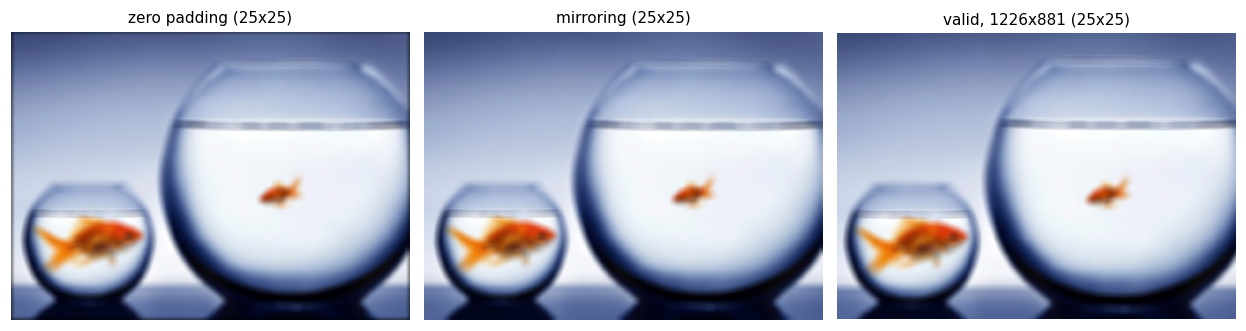

In [12]:
s = 25
b_zero = convolve_image(goldfish, make_box_filter(s), padding="zero")
b_reflect = blurred_imgs[s]
b_valid = convolve_image(goldfish, make_box_filter(s), padding="valid")
for name, im in [("1b_border_zero.png", b_zero), ("1b_border_reflect.png", b_reflect),
                 ("1b_border_valid.png", b_valid)]:
    save_image(name, im)

band = s // 2
edge_mask = np.zeros((H0, W0), bool)
edge_mask[:band, :] = edge_mask[-band:, :] = edge_mask[:, :band] = edge_mask[:, -band:] = True
dark = float(b_reflect[edge_mask].mean() - b_zero[edge_mask].mean())
print(f"border band of {band} px: zero padding is {dark:.1f} grey levels darker than mirroring on average")
print("valid output size:", b_valid.shape[1], "x", b_valid.shape[0], "(input", W0, "x", H0, ")")
RESULTS["1b_border"] = {"band_px": band, "zero_darker_by": dark, "valid_size": [b_valid.shape[1], b_valid.shape[0]]}

show_grid([b_zero, b_reflect, b_valid],
          [f"zero padding ({s}x{s})", f"mirroring ({s}x{s})", f"valid, {b_valid.shape[1]}x{b_valid.shape[0]} ({s}x{s})"],
          ncols=3, fig_name="1b_borders.png", cell=3.8)

---
# Exercise 2 – OpenCV: filtering and lines

## 2(a) Colour-based object segmentation

I convert the images from BGR to **HSV** with `cv2.cvtColor`.
In BGR, the brightness of a pixel is spread over all three channels. So the same red apple has very different
B, G, R values in the light and in the shadow. In HSV, the colour itself is in one channel (hue, H),
and the strength of the colour (saturation, S) and the brightness (value, V) are separate channels.
So one simple box in HSV can cover a fruit in the light and in the shadow.

In OpenCV (8-bit images), H goes from 0 to 179, and S and V go from 0 to 255.
Red is at both ends of the hue circle, so for red I need **two** ranges (one near 0 and one near 179) and I join them with OR.

**How I choose the thresholds.** For every image I plot the hue–saturation histogram and the value histogram.
I find the peak that belongs to the fruit and put the box around it. Then I check the mask by eye and adjust the limits.

apples.jpg        2892 x 2093
apples2.jpg       1800 x 2700
blackberries.jpg  288 x 304
cherries.jpg      640 x 427


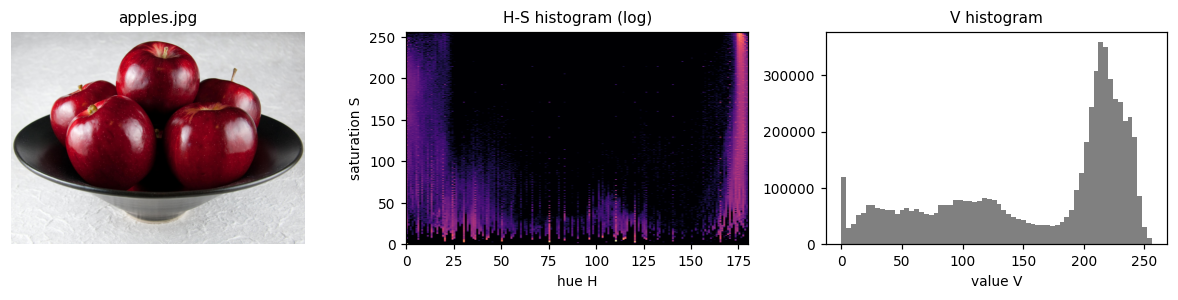

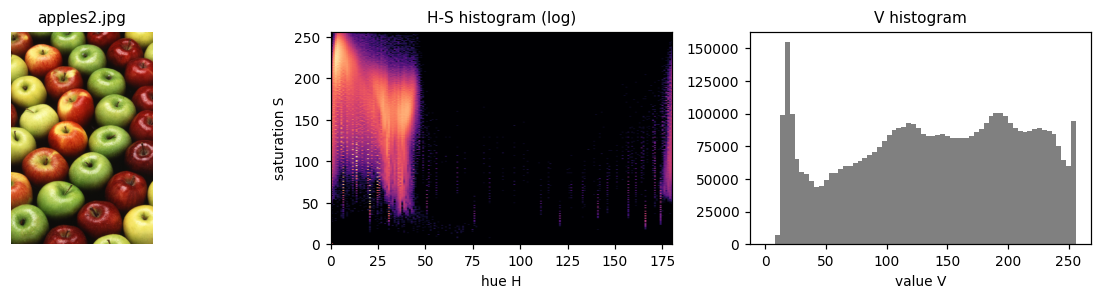

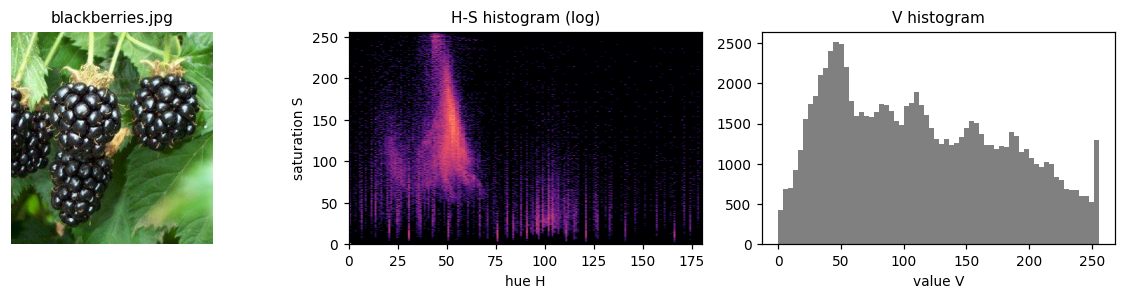

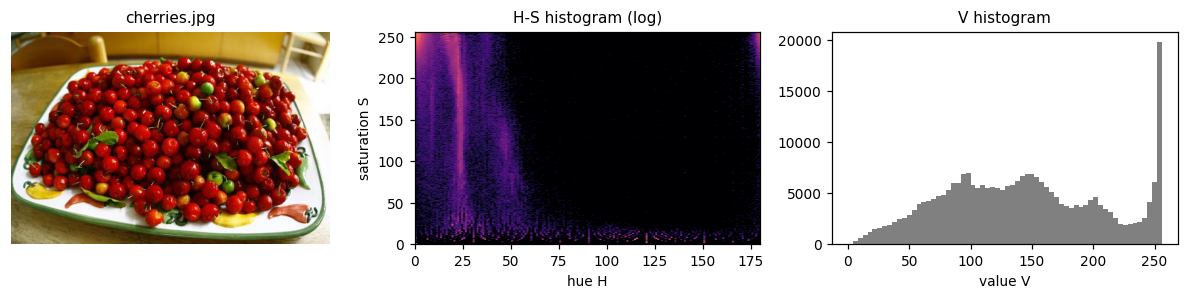

In [13]:
FRUIT_FILES = ["apples.jpg", "apples2.jpg", "blackberries.jpg", "cherries.jpg"]
fruits = {n: read_image(n) for n in FRUIT_FILES}
for n, im in fruits.items():
    print(f"{n:17s} {im.shape[1]} x {im.shape[0]}")


def hsv_histograms(name, img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
    ax[0].imshow(to_rgb(img)); ax[0].set_title(name); ax[0].axis("off")
    hs = cv2.calcHist([hsv], [0, 1], None, [180, 256], [0, 180, 0, 256])
    ax[1].imshow(np.log1p(hs).T, origin="lower", aspect="auto", cmap="magma", extent=[0, 180, 0, 256])
    ax[1].set_xlabel("hue H"); ax[1].set_ylabel("saturation S"); ax[1].set_title("H-S histogram (log)")
    ax[2].hist(hsv[..., 2].ravel(), bins=64, range=(0, 256), color="gray")
    ax[2].set_xlabel("value V"); ax[2].set_title("V histogram")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"2a_hist_{name.split('.')[0]}.png"))
    plt.show()


for n, im in fruits.items():
    hsv_histograms(n, im)

### Thresholds

Each image has a list of HSV boxes, written as `(H_low, S_low, V_low), (H_high, S_high, V_high)`.
A pixel is "fruit" if it falls inside any of the boxes. This is what I found from the histograms:

- **apples.jpg** – dark red apples in a black bowl. Two red ranges. The shadowed parts of the apples are quite dark (V around 30–60)
  but still very saturated, while the bowl and the background have almost no saturation. So I use a low V limit (35)
  and rely on S ≥ 100 to reject the bowl. A lower V limit also picks up the red reflections of the apples on the bowl.
- **apples2.jpg** – red, yellow and green apples packed together, with dark shadows between them. All of them are fruit,
  so I take all hues from red to green (H 0–85, plus the red end 160–179). The shadows are rejected with V ≥ 70.
- **blackberries.jpg** – the berries are almost black, but the shadows of the leaves are also dark, so V alone is not enough.
  I sampled pixels and found that dark leaf pixels are strongly saturated green (H 40–60, S > 140), while the berry pixels
  have low saturation, or a blue/purple hue (H 90–150) in their shiny highlights. So I use two boxes: "dark and weakly coloured" and "blue/purple".
- **cherries.jpg** – bright red cherries. Two red ranges with S ≥ 100 and V ≥ 40.

In [14]:
FRUIT_RANGES = {
    "apples.jpg":       [((0, 100, 35),  (10, 255, 255)),  ((160, 100, 35), (179, 255, 255))],
    "apples2.jpg":      [((0, 90, 70),   (85, 255, 255)),  ((160, 90, 70),  (179, 255, 255))],
    "blackberries.jpg": [((0, 0, 0),     (179, 90, 120)),  ((90, 0, 0),     (150, 255, 230))],
    "cherries.jpg":     [((0, 100, 40),  (10, 255, 255)),  ((160, 100, 40), (179, 255, 255))],
}
MIN_AREA_FRAC = 0.0005
MAX_HOLE_FRAC = 0.01
MIN_HOLE_V = 120

### Segmentation and cleaning

The function `segment_fruit` converts the image to HSV, runs `cv2.inRange` for every box and joins the masks with OR.
The raw mask is already the required binary output (255 = fruit, 0 = not fruit).

I also make a cleaned mask, because the raw mask has small false dots and holes:

1. A morphological **opening** removes small false dots, and a **closing** fills small gaps.
   The size of the round kernel grows with the image size (about 1/200 of the shorter side, at least 5 pixels),
   because the apple photos are much bigger than the cherry and blackberry photos.
2. Blobs smaller than 0.05% of the image are removed.
3. Holes inside a fruit blob are filled if they are smaller than 1% of the image **and** bright (mean V of at least 120).
   These are the white shiny spots on the fruit, which have almost no colour, so the thresholds miss them.
   Dark holes are not filled, because they are usually shadows between fruits (for example the gaps between the apples in `apples2.jpg`).

`overlay` draws the outline of the mask on the image so I can check the result by eye.

apples.jpg        fruit pixels: raw  28.6%  cleaned  32.4%   blobs: 2
apples2.jpg       fruit pixels: raw  77.6%  cleaned  79.2%   blobs: 6
blackberries.jpg  fruit pixels: raw  25.4%  cleaned  26.0%   blobs: 3
cherries.jpg      fruit pixels: raw  42.0%  cleaned  45.6%   blobs: 2


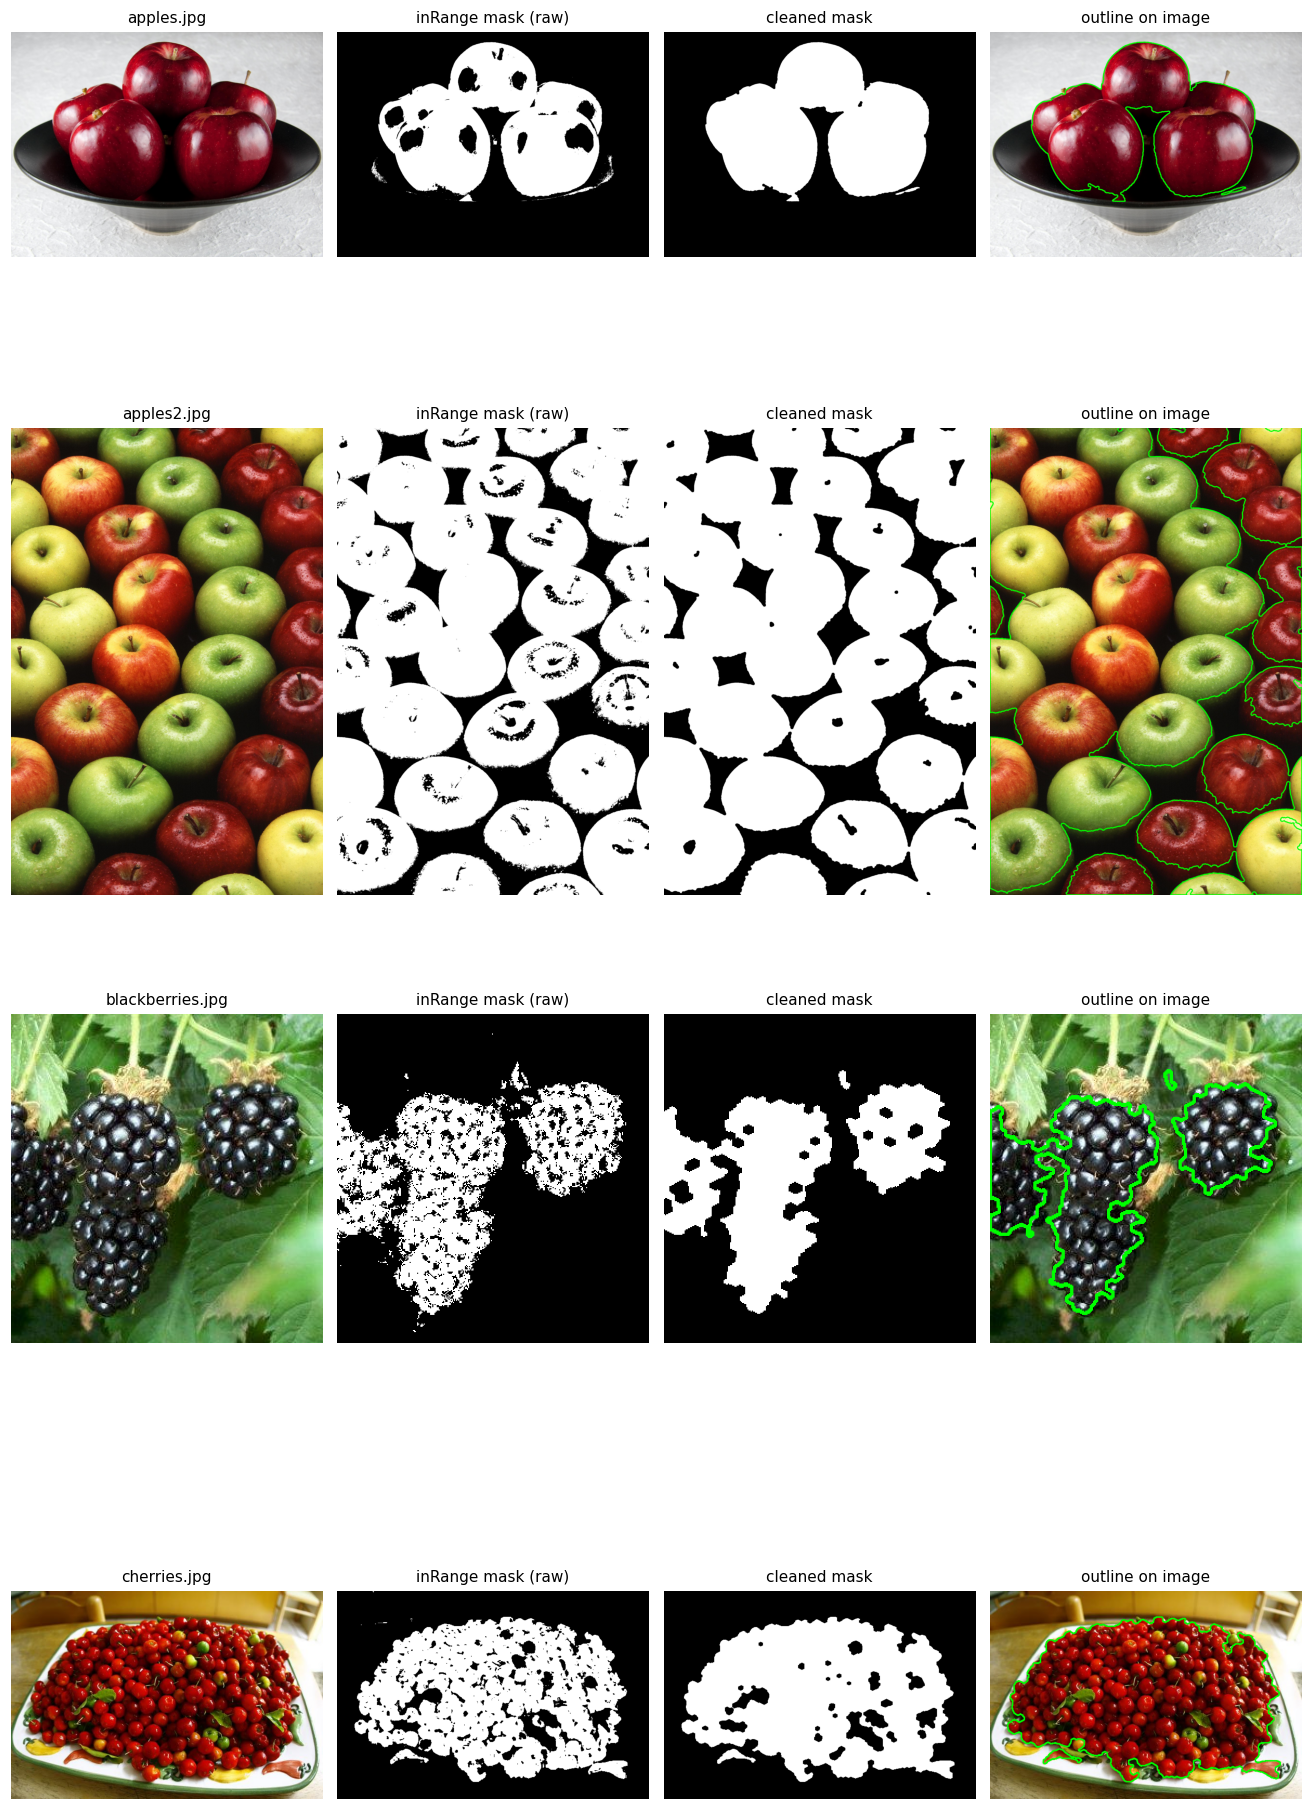

In [15]:
def segment_fruit(img_bgr, ranges, clean=True):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    mask = np.zeros(hsv.shape[:2], np.uint8)
    for lo, hi in ranges:
        mask = cv2.bitwise_or(mask, cv2.inRange(hsv, np.array(lo), np.array(hi)))
    if not clean:
        return mask

    ks = max(5, round(min(mask.shape) / 200)) | 1
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ks, ks))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)

    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= MIN_AREA_FRAC * mask.size
    mask = np.where(keep[labels], 255, 0).astype(np.uint8)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    cv2.drawContours(filled, contours, -1, 255, thickness=-1)
    holes = cv2.subtract(filled, mask)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(holes, connectivity=8)
    mean_v = np.bincount(labels.ravel(), weights=hsv[..., 2].ravel(), minlength=n) / np.maximum(stats[:, cv2.CC_STAT_AREA], 1)
    fill = np.zeros(n, bool)
    fill[1:] = (stats[1:, cv2.CC_STAT_AREA] < MAX_HOLE_FRAC * mask.size) & (mean_v[1:] >= MIN_HOLE_V)
    return cv2.bitwise_or(mask, np.where(fill[labels], 255, 0).astype(np.uint8))


def overlay(img, mask, color=(0, 255, 0)):
    out = img.copy()
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, contours, -1, color, max(2, img.shape[1] // 300))
    return out


seg_stats = {}
panels, titles = [], []
for n, im in fruits.items():
    raw = segment_fruit(im, FRUIT_RANGES[n], clean=False)
    clean = segment_fruit(im, FRUIT_RANGES[n], clean=True)
    base = n.split(".")[0]
    save_image(f"2a_{base}_mask_raw.png", raw)
    save_image(f"2a_{base}_mask.png", clean)
    save_image(f"2a_{base}_overlay.png", overlay(im, clean))
    n_blobs = cv2.connectedComponents(clean)[0] - 1
    seg_stats[n] = {"fruit_fraction_raw": float((raw > 0).mean()),
                    "fruit_fraction_clean": float((clean > 0).mean()), "blobs": int(n_blobs)}
    panels += [im, raw, clean, overlay(im, clean)]
    titles += [n, "inRange mask (raw)", "cleaned mask", "outline on image"]
    print(f"{n:17s} fruit pixels: raw {100 * seg_stats[n]['fruit_fraction_raw']:5.1f}%  "
          f"cleaned {100 * seg_stats[n]['fruit_fraction_clean']:5.1f}%   blobs: {n_blobs}")
RESULTS["2a"] = seg_stats
RESULTS["2a_ranges"] = FRUIT_RANGES

show_grid(panels, titles, ncols=4, fig_name="2a_segmentation.png", cell=3.0, interp="antialiased")

### Why HSV and not BGR?

To show why I picked HSV, I also try to segment `apples.jpg` directly in BGR.
I take the fruit pixels found with HSV and build the tightest BGR box that holds 90% of them
(the 5th to 95th percentile of each channel). This is a "best case" BGR box, because it is built from the answer.
Then I check how many fruit pixels it keeps and how many background pixels it wrongly marks as fruit.

BGR box: low [ 7  0 45] high [ 96  85 195]
BGR mask keeps 86.1% of the HSV fruit pixels and marks 3.9% of the non-fruit pixels as fruit


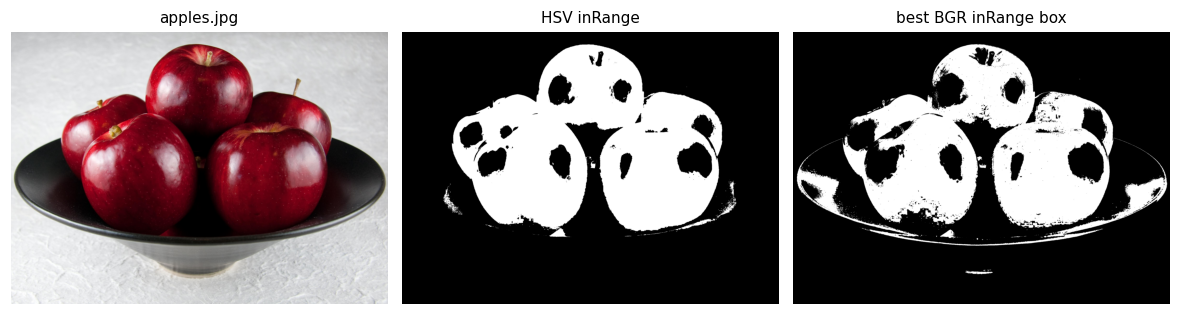

In [16]:
n = "apples.jpg"
im = fruits[n]
hsv_mask = segment_fruit(im, FRUIT_RANGES[n], clean=False)
fruit_px = im[hsv_mask > 0]
lo = np.percentile(fruit_px, 5, axis=0).astype(np.uint8)
hi = np.percentile(fruit_px, 95, axis=0).astype(np.uint8)
bgr_mask = cv2.inRange(im, lo, hi)
agree = float(((bgr_mask > 0) == (hsv_mask > 0)).mean())
inside = float((bgr_mask[hsv_mask > 0] > 0).mean())
outside = float((bgr_mask[hsv_mask == 0] > 0).mean())
print("BGR box: low", lo, "high", hi)
print(f"BGR mask keeps {100 * inside:.1f}% of the HSV fruit pixels and marks "
      f"{100 * outside:.1f}% of the non-fruit pixels as fruit")
RESULTS["2a_bgr_vs_hsv"] = {"bgr_low": lo.tolist(), "bgr_high": hi.tolist(),
                            "kept_fruit": inside, "false_fruit": outside, "agreement": agree}
save_image("2a_apples_mask_bgr.png", bgr_mask)
show_grid([im, hsv_mask, bgr_mask], [n, "HSV inRange", "best BGR inRange box"],
          ncols=3, fig_name="2a_bgr_vs_hsv.png", cell=3.6, interp="antialiased")

## 2(b) Edge detection

### On the clean image

My pipeline on the grayscale image `blox.jpg` has four parts:

1. **Sobel.** `cv2.Sobel` gives the derivatives $G_x$ and $G_y$. The gradient magnitude $\sqrt{G_x^2 + G_y^2}$
   is large on edges. I divide it by 4 so it fits roughly in 0–255, and then keep only the strong edges with `cv2.threshold`.
   The threshold is found with Otsu's method on the clean image, and then I keep it **fixed** for the noisy images, so the comparison is fair.
2. **Canny.** `cv2.Canny` with thresholds 50 and 150. It gives thin, connected edges (non-maximum suppression, then hysteresis
   with a low and a high threshold). These thresholds are also kept fixed.
3. **Gray-level thresholding (regions).** `cv2.threshold` with Otsu splits the image into bright regions and dark regions.
   `cv2.inRange` keeps only one band of gray levels (100–170), so I can pick out the parts of the scene with a certain brightness.
   The border of the Otsu regions (morphological gradient) gives region edges.
4. **Combined edges.** I keep only the Canny edges that are close to a strong Sobel response.
   This removes weak edges and keeps the main object outlines.

blox.jpg: 256 x 256 | min 0 max 252
Sobel threshold (Otsu on the clean image): 36.0


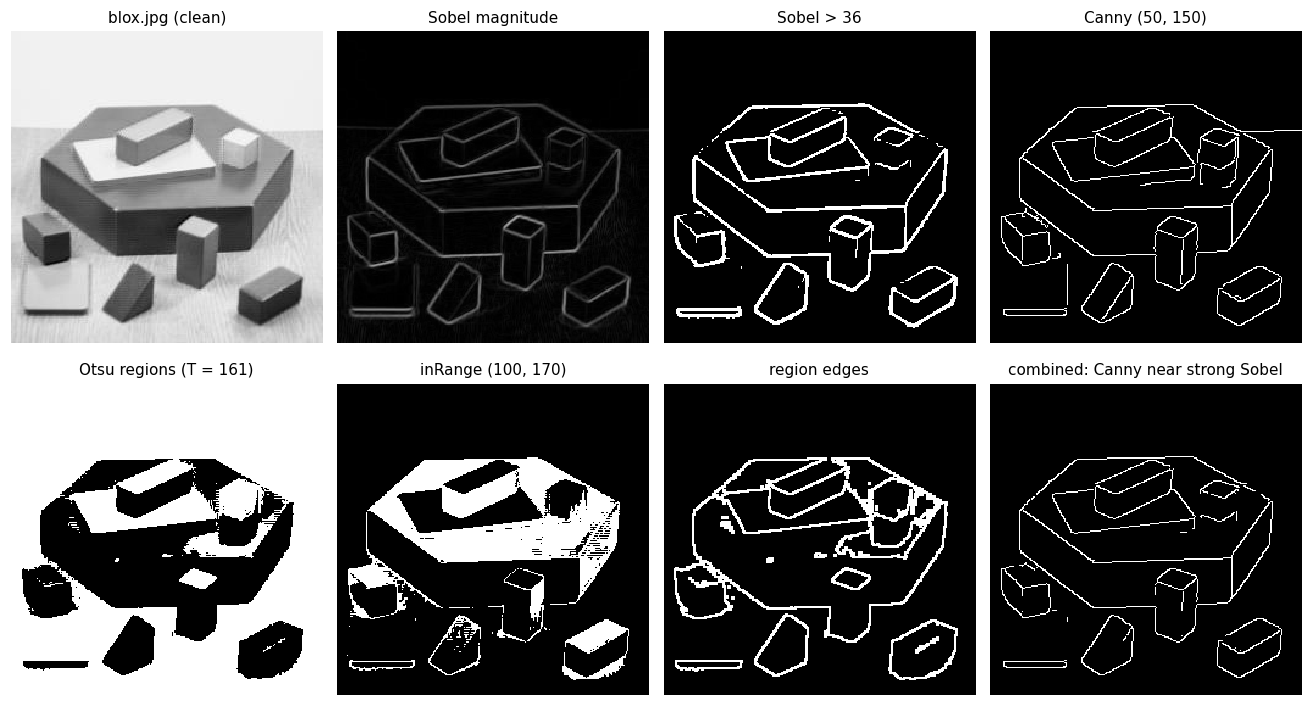

In [17]:
blox = read_image("blox.jpg", cv2.IMREAD_GRAYSCALE)
print("blox.jpg:", blox.shape[1], "x", blox.shape[0], "| min", blox.min(), "max", blox.max())

SOBEL_SCALE = 4.0
CANNY_LOW, CANNY_HIGH = 50, 150
INRANGE_BAND = (100, 170)


def sobel_magnitude(gray):
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return np.clip(np.sqrt(gx ** 2 + gy ** 2) / SOBEL_SCALE, 0, 255).astype(np.uint8)


SOBEL_T, _ = cv2.threshold(sobel_magnitude(blox), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Sobel threshold (Otsu on the clean image):", SOBEL_T)


def edge_pipeline(gray):
    r = {}
    r["sobel_mag"] = sobel_magnitude(gray)
    _, r["sobel_edges"] = cv2.threshold(r["sobel_mag"], SOBEL_T, 255, cv2.THRESH_BINARY)
    r["canny"] = cv2.Canny(gray, CANNY_LOW, CANNY_HIGH, L2gradient=True)
    r["otsu_T"], r["regions"] = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    r["band"] = cv2.inRange(gray, INRANGE_BAND[0], INRANGE_BAND[1])
    k = np.ones((3, 3), np.uint8)
    r["region_edges"] = cv2.morphologyEx(r["regions"], cv2.MORPH_GRADIENT, k)
    near_strong = cv2.dilate(r["sobel_edges"], k)
    r["combined"] = cv2.bitwise_and(r["canny"], near_strong)
    return r


def show_pipeline(gray, r, title, fig_name):
    show_grid([gray, r["sobel_mag"], r["sobel_edges"], r["canny"],
               r["regions"], r["band"], r["region_edges"], r["combined"]],
              [title, "Sobel magnitude", f"Sobel > {SOBEL_T:.0f}", f"Canny ({CANNY_LOW}, {CANNY_HIGH})",
               f"Otsu regions (T = {r['otsu_T']:.0f})", f"inRange {INRANGE_BAND}", "region edges",
               "combined: Canny near strong Sobel"],
              ncols=4, fig_name=fig_name, cell=3.0)


clean_r = edge_pipeline(blox)
show_pipeline(blox, clean_r, "blox.jpg (clean)", "2b_clean_pipeline.png")
for k in ["sobel_mag", "sobel_edges", "canny", "regions", "band", "region_edges", "combined"]:
    save_image(f"2b_clean_{k}.png", clean_r[k])
RESULTS["2b_clean"] = {"sobel_T": float(SOBEL_T), "otsu_T": float(clean_r["otsu_T"]),
                       "canny_pixels": int((clean_r["canny"] > 0).sum()),
                       "range": [int(blox.min()), int(blox.max())]}

### Adding white Gaussian noise with a given PSNR

From the definition in the assignment I can solve for $\sigma_n$:

$$PSNR = 20\log_{10}\frac{I_{max} - I_{min}}{\sigma_n}
\quad\Longrightarrow\quad
\sigma_n = \frac{I_{max} - I_{min}}{10^{PSNR/20}} .$$

I compute $\sigma_n$ for 20 dB and 10 dB, add noise with `numpy.random.normal` (zero mean), and clip the result to 0–255
so it is still a valid 8-bit image. Clipping cuts off a part of the noise at very dark and very bright pixels,
so the real noise is a bit smaller than planned. Because of this I also measure the PSNR that the noisy image really has
(using the measured standard deviation of $I - I_0$). I use a fixed random seed so every run gives the same numbers.

**How I measure edge quality.** I use the Canny edges of the clean image as the reference. For an edge map from a noisy image I count:

- *precision* = the share of the found edge pixels that are within 1 pixel of a reference edge (how many found edges are real),
- *recall* = the share of the reference edge pixels that have a found edge within 1 pixel (how many real edges were found),
- *F1 score* = $2PR/(P+R)$, which combines both (1 = perfect, close to 0 = useless).

In [18]:
def sigma_for_psnr(gray, psnr_db):
    return (float(gray.max()) - float(gray.min())) / (10 ** (psnr_db / 20))


def add_gaussian_noise(gray, sigma, seed=0):
    np.random.seed(seed)
    noisy = gray.astype(np.float64) + np.random.normal(0, sigma, gray.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def measured_psnr(clean, test):
    s = np.std(test.astype(np.float64) - clean.astype(np.float64))
    return 20 * np.log10((float(clean.max()) - float(clean.min())) / s), s


def edge_scores(edges, reference, tol=1):
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    e, ref = edges > 0, reference > 0
    if e.sum() == 0:
        return 0.0, 0.0, 0.0
    precision = (e & (cv2.dilate(reference, k) > 0)).sum() / e.sum()
    recall = (ref & (cv2.dilate(edges, k) > 0)).sum() / ref.sum()
    f1 = 0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return float(precision), float(recall), float(f1)

PSNR 20 dB: sigma_n = 25.20  (after clipping: sigma = 23.29, PSNR = 20.69 dB)
    sobel_edges  precision 0.355  recall 0.992  F1 0.523
    canny        precision 0.153  recall 0.996  F1 0.265
    combined     precision 0.191  recall 0.996  F1 0.320


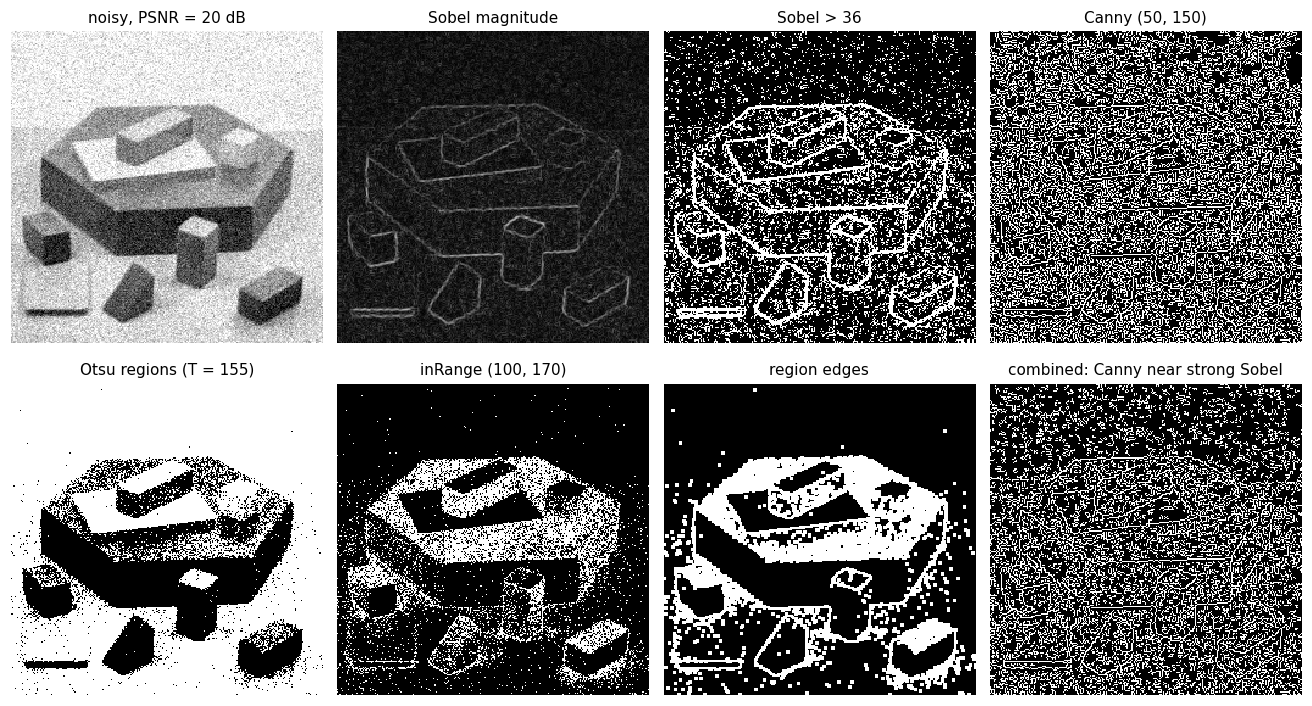

PSNR 10 dB: sigma_n = 79.69  (after clipping: sigma = 62.24, PSNR = 12.15 dB)
    sobel_edges  precision 0.154  recall 1.000  F1 0.267
    canny        precision 0.144  recall 0.997  F1 0.251
    combined     precision 0.144  recall 0.997  F1 0.252


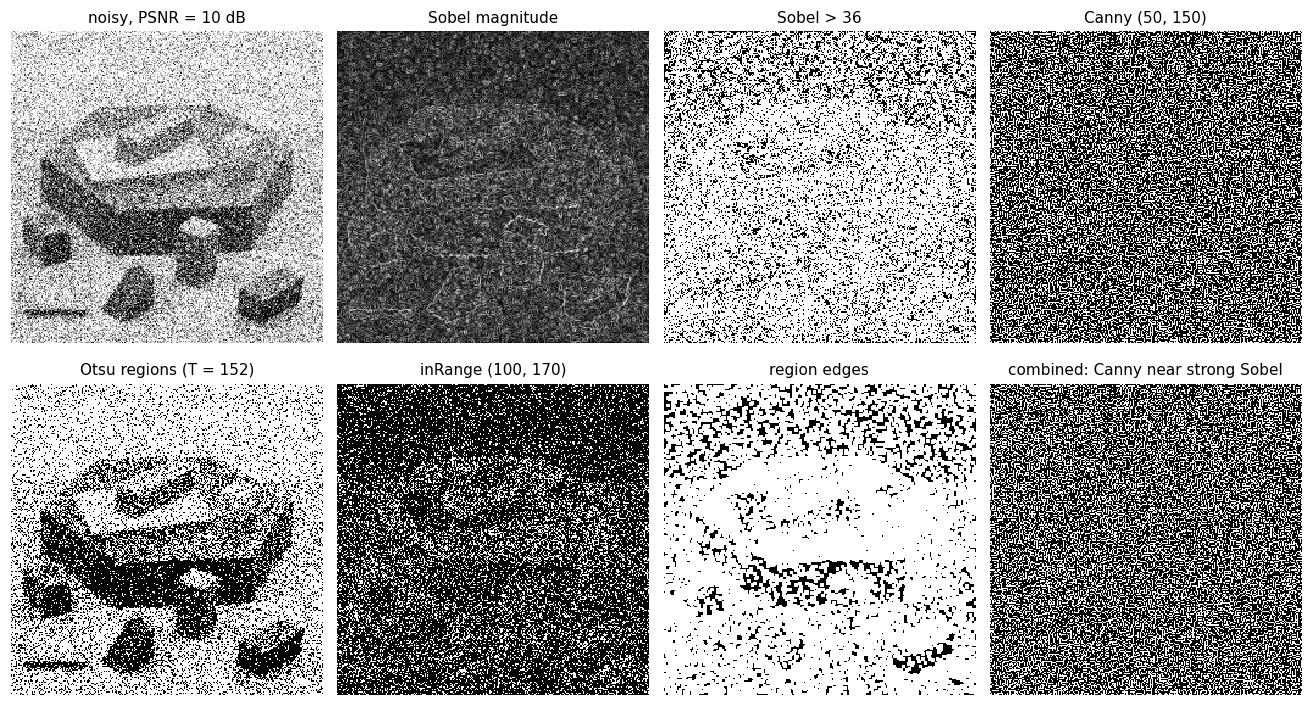

clean image: {'sobel_edges': 0.933, 'canny': 1.0, 'combined': 0.945}


In [19]:
REF = clean_r["canny"]
noisy, noisy_r = {}, {}
RESULTS["2b_noise"] = {}
for psnr in [20, 10]:
    sigma = sigma_for_psnr(blox, psnr)
    noisy[psnr] = add_gaussian_noise(blox, sigma, seed=psnr)
    real_psnr, real_sigma = measured_psnr(blox, noisy[psnr])
    noisy_r[psnr] = edge_pipeline(noisy[psnr])
    save_image(f"2b_noisy_{psnr}dB.png", noisy[psnr])
    for k in ["sobel_edges", "canny", "regions", "band", "combined"]:
        save_image(f"2b_noisy_{psnr}dB_{k}.png", noisy_r[psnr][k])
    sc = {k: edge_scores(noisy_r[psnr][k], REF) for k in ["sobel_edges", "canny", "combined"]}
    RESULTS["2b_noise"][psnr] = {"sigma": sigma, "measured_sigma": real_sigma, "measured_psnr": real_psnr,
                                 "otsu_T": float(noisy_r[psnr]["otsu_T"]), "scores": sc,
                                 "edge_pixels": {k: int((noisy_r[psnr][k] > 0).sum())
                                                 for k in ["sobel_edges", "canny", "combined"]}}
    print(f"PSNR {psnr} dB: sigma_n = {sigma:.2f}  (after clipping: sigma = {real_sigma:.2f}, PSNR = {real_psnr:.2f} dB)")
    for k, (p, r_, f) in sc.items():
        print(f"    {k:12s} precision {p:.3f}  recall {r_:.3f}  F1 {f:.3f}")
    show_pipeline(noisy[psnr], noisy_r[psnr], f"noisy, PSNR = {psnr} dB", f"2b_noisy_{psnr}dB_pipeline.png")

sc_clean = {k: edge_scores(clean_r[k], REF) for k in ["sobel_edges", "canny", "combined"]}
RESULTS["2b_clean"]["scores"] = sc_clean
print("clean image:", {k: round(v[2], 3) for k, v in sc_clean.items()})

### Denoising before edge detection

I try the smoothing filters that we saw in class, each with a few parameter values:

- **Box filter** (`cv2.blur`): plain average of the neighbourhood.
- **Gaussian filter** (`cv2.GaussianBlur`): weighted average, close pixels count more.
- **Median filter** (`cv2.medianBlur`): the middle value of the neighbourhood.
- **Bilateral filter** (`cv2.bilateralFilter`): averages only pixels that are close *and* have a similar gray level,
  so it tries to keep edges. I write the settings as diameter / $\sigma_{color}$ / $\sigma_{space}$.
- **Non-local means** (`cv2.fastNlMeansDenoising`): averages pixels whose surrounding patches look alike, even if they are far apart.
  A bigger $h$ means stronger smoothing.

For every result I measure the noise that is left (PSNR of the denoised image against the clean one, same definition as above)
and the edge F1 score of Canny, Sobel and the combined edges. The edge thresholds stay the same as on the clean image.

In [21]:
DENOISERS = {
    "box 3x3":             lambda g: cv2.blur(g, (3, 3)),
    "box 5x5":             lambda g: cv2.blur(g, (5, 5)),
    "box 7x7":             lambda g: cv2.blur(g, (7, 7)),
    "Gaussian s=1":        lambda g: cv2.GaussianBlur(g, (0, 0), 1),
    "Gaussian s=2":        lambda g: cv2.GaussianBlur(g, (0, 0), 2),
    "Gaussian s=3":        lambda g: cv2.GaussianBlur(g, (0, 0), 3),
    "median 3":            lambda g: cv2.medianBlur(g, 3),
    "median 5":            lambda g: cv2.medianBlur(g, 5),
    "median 7":            lambda g: cv2.medianBlur(g, 7),
    "bilateral 9/50/50":   lambda g: cv2.bilateralFilter(g, 9, 50, 50),
    "bilateral 9/100/50":  lambda g: cv2.bilateralFilter(g, 9, 100, 50),
    "bilateral 15/150/50": lambda g: cv2.bilateralFilter(g, 15, 150, 50),
    "NL-means h=15":       lambda g: cv2.fastNlMeansDenoising(g, None, h=15, templateWindowSize=7, searchWindowSize=21),
    "NL-means h=30":       lambda g: cv2.fastNlMeansDenoising(g, None, h=30, templateWindowSize=7, searchWindowSize=21),
    "NL-means h=60":       lambda g: cv2.fastNlMeansDenoising(g, None, h=60, templateWindowSize=7, searchWindowSize=21),
}

table = {}
denoised = {}
for psnr in [20, 10]:
    table[psnr] = {}
    base = edge_scores(noisy_r[psnr]["canny"], REF)[2]
    print(f"\n=== PSNR {psnr} dB  (no denoising: Canny F1 = {base:.3f}) ===")
    print(f"{'method':20s} {'PSNR after':>10s} {'Canny F1':>9s} {'Sobel F1':>9s} {'Comb. F1':>9s}")
    for name, fn in DENOISERS.items():
        d = fn(noisy[psnr])
        denoised[(psnr, name)] = d
        r = edge_pipeline(d)
        p_after = measured_psnr(blox, d)[0]
        f_c = edge_scores(r["canny"], REF)[2]
        f_s = edge_scores(r["sobel_edges"], REF)[2]
        f_m = edge_scores(r["combined"], REF)[2]
        table[psnr][name] = {"psnr_after": p_after, "canny_f1": f_c, "sobel_f1": f_s, "combined_f1": f_m}
        print(f"{name:20s} {p_after:10.2f} {f_c:9.3f} {f_s:9.3f} {f_m:9.3f}")
RESULTS["2b_denoise"] = table


=== PSNR 20 dB  (no denoising: Canny F1 = 0.265) ===
method               PSNR after  Canny F1  Sobel F1  Comb. F1
box 3x3                   28.72     0.846     0.886     0.910
box 5x5                   28.70     0.862     0.711     0.757
box 7x7                   26.99     0.617     0.403     0.426
Gaussian s=1              29.54     0.894     0.870     0.901
Gaussian s=2              27.89     0.841     0.560     0.598
Gaussian s=3              25.45     0.503     0.096     0.110
median 3                  27.19     0.532     0.886     0.817
median 5                  29.26     0.872     0.841     0.864
median 7                  29.00     0.850     0.757     0.780
bilateral 9/50/50         29.26     0.870     0.861     0.876
bilateral 9/100/50        29.16     0.847     0.725     0.747
bilateral 15/150/50       25.20     0.606     0.382     0.418
NL-means h=15             24.94     0.519     0.812     0.658
NL-means h=30             31.13     0.894     0.793     0.807
NL-means h=60   

Now I plot the Canny F1 score of every setting for both noise levels. Then, for every filter type, I pick the setting
with the best Canny F1 and show the denoised image next to its Canny edges.

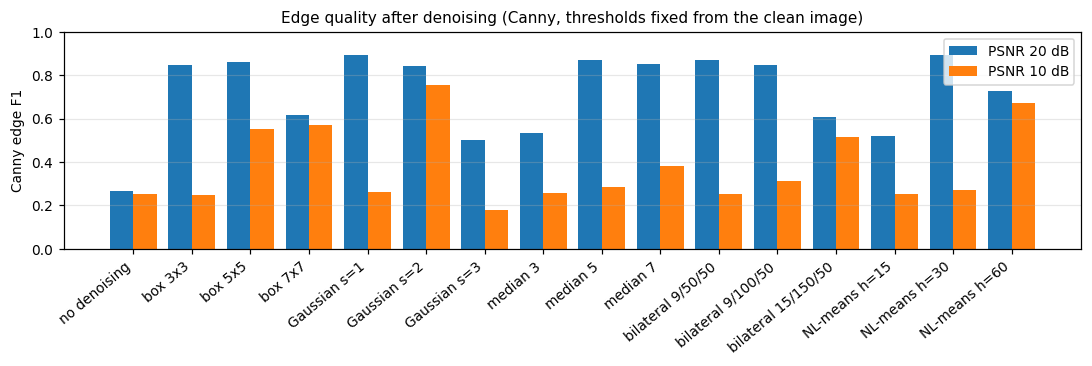

PSNR 20 dB: best per family {'box': 'box 5x5', 'Gaussian': 'Gaussian s=1', 'median': 'median 5', 'bilateral': 'bilateral 9/50/50', 'NL-means': 'NL-means h=30', 'overall': 'NL-means h=30'}
PSNR 10 dB: best per family {'box': 'box 7x7', 'Gaussian': 'Gaussian s=2', 'median': 'median 7', 'bilateral': 'bilateral 15/150/50', 'NL-means': 'NL-means h=60', 'overall': 'Gaussian s=2'}


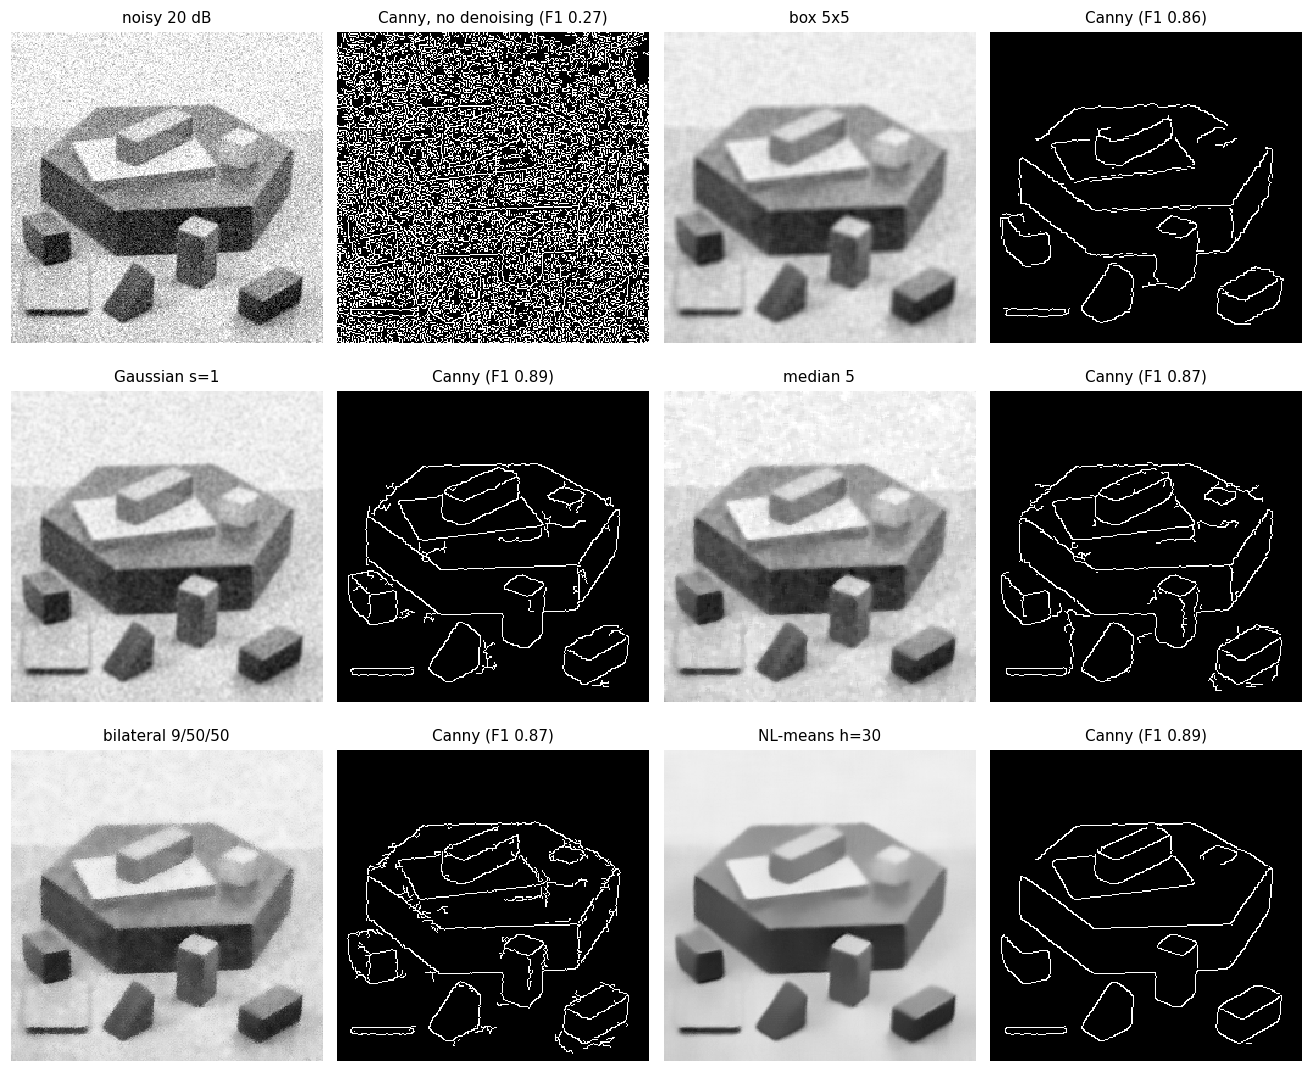

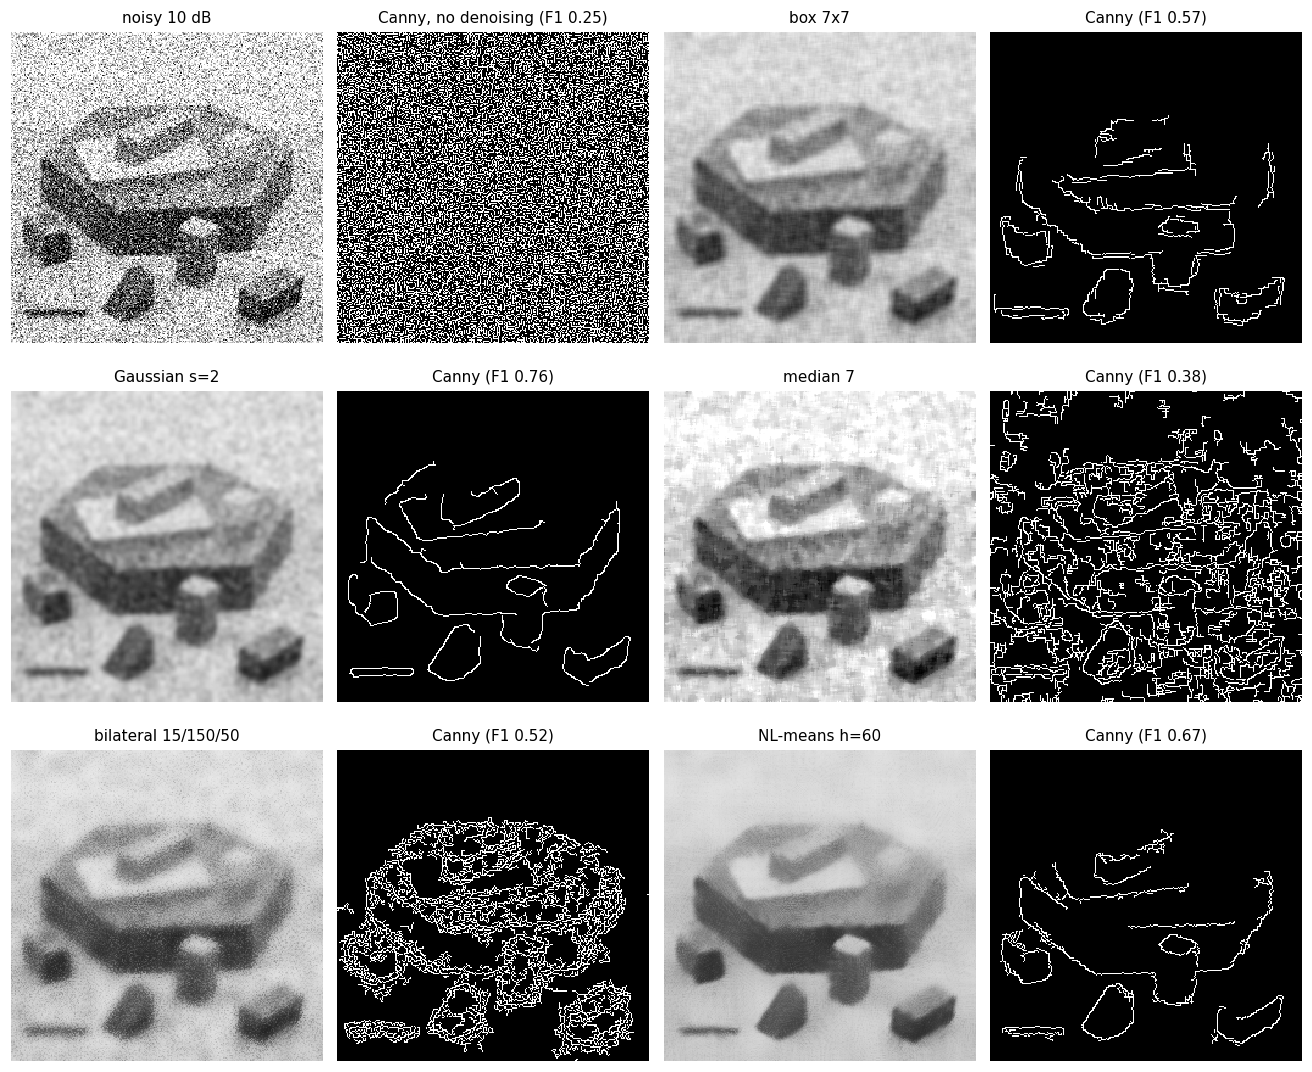

In [23]:
names = list(DENOISERS)
x = np.arange(len(names) + 1)
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, psnr in enumerate([20, 10]):
    vals = [edge_scores(noisy_r[psnr]["canny"], REF)[2]] + [table[psnr][n]["canny_f1"] for n in names]
    ax.bar(x + (i - 0.5) * 0.4, vals, width=0.4, label=f"PSNR {psnr} dB")
ax.set_xticks(x); ax.set_xticklabels(["no denoising"] + names, rotation=40, ha="right")
ax.set_ylabel("Canny edge F1"); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=.3); ax.legend()
ax.set_title("Edge quality after denoising (Canny, thresholds fixed from the clean image)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "2b_denoise_f1.png")); plt.show()

families = ["box", "Gaussian", "median", "bilateral", "NL-means"]
best = {}
for psnr in [20, 10]:
    best[psnr] = {}
    for fam in families:
        cands = [n for n in names if n.startswith(fam)]
        best[psnr][fam] = max(cands, key=lambda n: table[psnr][n]["canny_f1"])
    best[psnr]["overall"] = max(names, key=lambda n: table[psnr][n]["canny_f1"])
    print(f"PSNR {psnr} dB: best per family {best[psnr]}")
RESULTS["2b_best"] = best

for psnr in [20, 10]:
    imgs = [noisy[psnr], noisy_r[psnr]["canny"]]
    tts = [f"noisy {psnr} dB", f"Canny, no denoising (F1 {edge_scores(noisy_r[psnr]['canny'], REF)[2]:.2f})"]
    for fam in families:
        n = best[psnr][fam]
        d = denoised[(psnr, n)]
        r = edge_pipeline(d)
        tag = fam.replace("-", "").replace(" ", "")
        save_image(f"2b_denoised_{psnr}dB_{tag}.png", d)
        save_image(f"2b_denoised_{psnr}dB_{tag}_canny.png", r["canny"])
        imgs += [d, r["canny"]]
        tts += [n, f"Canny (F1 {table[psnr][n]['canny_f1']:.2f})"]
    show_grid(imgs, tts, ncols=4, fig_name=f"2b_denoise_{psnr}dB.png", cell=3.0)

### Can we just raise the Canny thresholds?

Instead of smoothing, one could also just raise the Canny thresholds so the weak noise edges are dropped.
Here I test a few threshold pairs on the noisy images, without denoising and with the best denoiser for that noise level.

In [24]:
pairs = [(50, 150), (100, 200), (150, 300), (200, 400), (300, 600)]
RESULTS["2b_canny_thresholds"] = {}
for psnr in [20, 10]:
    best_d = denoised[(psnr, best[psnr]["overall"])]
    row = {}
    for lo, hi in pairs:
        f_raw = edge_scores(cv2.Canny(noisy[psnr], lo, hi, L2gradient=True), REF)[2]
        f_den = edge_scores(cv2.Canny(best_d, lo, hi, L2gradient=True), REF)[2]
        row[f"{lo}/{hi}"] = {"noisy": f_raw, "denoised": f_den}
    RESULTS["2b_canny_thresholds"][psnr] = row
    print(f"PSNR {psnr} dB (denoiser: {best[psnr]['overall']})")
    for k, v in row.items():
        print(f"   Canny {k:8s}  F1 noisy {v['noisy']:.3f}   F1 denoised {v['denoised']:.3f}")

PSNR 20 dB (denoiser: NL-means h=30)
   Canny 50/150    F1 noisy 0.265   F1 denoised 0.894
   Canny 100/200   F1 noisy 0.375   F1 denoised 0.848
   Canny 150/300   F1 noisy 0.781   F1 denoised 0.715
   Canny 200/400   F1 noisy 0.764   F1 denoised 0.598
   Canny 300/600   F1 noisy 0.327   F1 denoised 0.000
PSNR 10 dB (denoiser: Gaussian s=2)
   Canny 50/150    F1 noisy 0.251   F1 denoised 0.755
   Canny 100/200   F1 noisy 0.253   F1 denoised 0.465
   Canny 150/300   F1 noisy 0.260   F1 denoised 0.000
   Canny 200/400   F1 noisy 0.282   F1 denoised 0.000
   Canny 300/600   F1 noisy 0.428   F1 denoised 0.000


### Saving the numbers

Finally, I save all the numbers in `outputs/results.json`. NumPy numbers are turned into normal Python numbers first,
because `json` cannot save them directly.

In [25]:
def to_plain(o):
    if isinstance(o, dict):
        return {str(k): to_plain(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_plain(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o


with open(os.path.join(OUT_DIR, "results.json"), "w") as fh:
    json.dump(to_plain(RESULTS), fh, indent=2)
print("Saved", len(os.listdir(OUT_DIR)), "files in", OUT_DIR)

Saved 91 files in outputs
